# ☂️ Traditional Thai Parasol 3D Reconstruction Pipeline
**Computer Vision Project | Photogrammetry, Structure-from-Motion (PyCOLMAP) & Open3D**

This notebook implements the complete end-to-end 3D reconstruction pipeline:
1. **Stage 0: Video Frame Extraction** (High-FPS multi-elevation frame sampling)
2. **Stage 1: Image Preprocessing & AI Background Removal** (Standardizing, blur analysis & `rembg` black-masking)
3. **Stage 2: Feature Detection, Matching & Sparse SfM** (PyCOLMAP SIFT extraction, exhaustive two-view matching, bundle adjustment)
4. **Stage 3: 3D Point Cloud Outlier Filtering & HD Mesh Reconstruction** (Poisson surface reconstruction, Taubin smoothing, KNN color blending)
5. **Stage 4: Interactive 3D Visualization & Turntable Rendering** (In-notebook 3D mesh rendering & multi-angle snapshots)


In [9]:
# 1. Imports & Environment Setup
import os
import sys
import glob
import shutil
import sqlite3
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image

import pycolmap
import open3d as o3d
from rembg import new_session, remove

print(f"PyCOLMAP Version: {pycolmap.__version__}")
print(f"Open3D Version:   {o3d.__version__}")
print(f"OpenCV Version:   {cv2.__version__}")

# Set root project path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "project" else Path(".").resolve()
print(f"Project Root:     {PROJECT_ROOT}")


PyCOLMAP Version: 4.1.1
Open3D Version:   0.19.0
OpenCV Version:   5.0.0
Project Root:     /Users/y2k/school/1_2026/cv/project


---
## 🎬 Stage 0: Video Frame Extraction
Extracts frames at a target sampling rate (e.g. 6.0–8.0 FPS) from raw video files (`data/raw_videos/`).


In [10]:
def extract_frames(video_path, save_dir, target_fps=8.0):
    video_path = Path(video_path)
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    source_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    frame_interval = max(1, round(source_fps / target_fps))
    frame_idx, saved_idx = 0, 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_idx % frame_interval == 0:
            out_path = save_dir / f"frame_{saved_idx:04d}.jpg"
            cv2.imwrite(str(out_path), frame)
            saved_idx += 1
        frame_idx += 1

    cap.release()
    print(f"Extracted {saved_idx} frames from {video_path.name} -> {save_dir}")
    return saved_idx

# Example: extract if raw video exists
raw_video = PROJECT_ROOT / "data/raw_videos/source1.mp4"
frames_output = PROJECT_ROOT / "data/frames/source1"
if raw_video.exists():
    extract_frames(raw_video, frames_output, target_fps=8.0)


Extracted 80 frames from source1.mp4 -> /Users/y2k/school/1_2026/cv/project/data/frames/source1


---
## 📸 Stage 1: Image Preprocessing & AI Background Removal
Masks the stationary background to solid black `(0, 0, 0)`.
Because solid black has zero intensity gradient, SIFT feature extraction detects keypoints **strictly on the target object**.


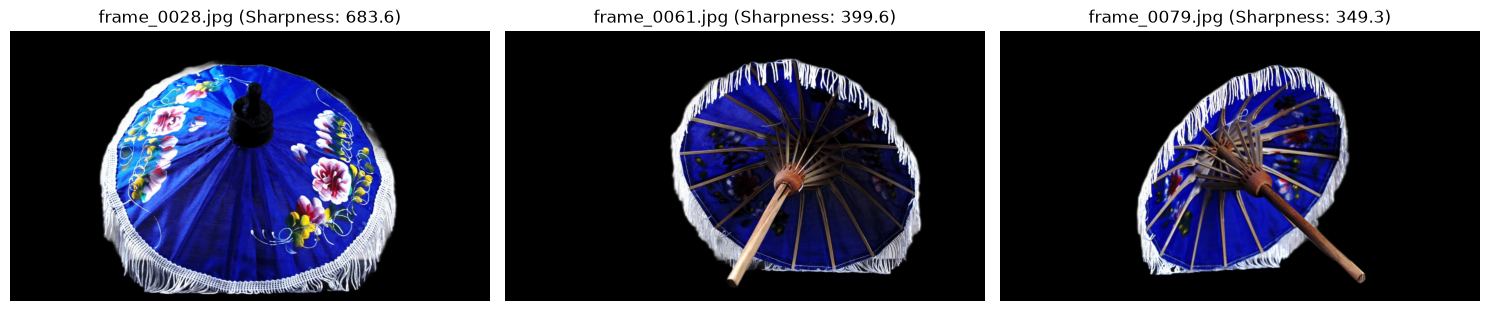

In [11]:
def blur_score(gray_img):
    return cv2.Laplacian(gray_img, cv2.CV_64F).var()

def preprocess_images(input_dir, output_dir, target_width=1280, blur_threshold=80.0, remove_bg=True, model_name="u2netp"):
    input_dir = Path(input_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    image_paths = sorted(p for p in input_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    if not image_paths:
        print(f"No images in {input_dir}")
        return

    session = new_session(model_name) if remove_bg else None
    print(f"Processing {len(image_paths)} images (remove_bg={remove_bg})...")

    for idx, img_path in enumerate(image_paths):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        if target_width and w != target_width:
            img_resized = cv2.resize(img, (target_width, int(h * target_width / w)), interpolation=cv2.INTER_AREA)
        else:
            img_resized = img

        if remove_bg and session is not None:
            pil_img = Image.fromarray(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
            rgba_img = remove(pil_img, session=session)
            bg = Image.new("RGBA", rgba_img.size, (0, 0, 0, 255))
            composite = Image.alpha_composite(bg, rgba_img).convert("RGB")
            final_img = cv2.cvtColor(np.array(composite), cv2.COLOR_RGB2BGR)
        else:
            final_img = img_resized

        cv2.imwrite(str(output_dir / img_path.name), final_img)

    print(f"Preprocessing complete -> {output_dir}")

# Preview preprocessed masked sample
preprocessed_dir = PROJECT_ROOT / "data/preprocessed/cv-1"
sample_files = list(preprocessed_dir.glob("*.jpg")) if preprocessed_dir.exists() else []

if sample_files:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for i, ax in enumerate(axes):
        idx = (i * len(sample_files)) // 3
        img_rgb = cv2.cvtColor(cv2.imread(str(sample_files[idx])), cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        ax.set_title(f"{sample_files[idx].name} (Sharpness: {blur_score(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)):.1f})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


---
## 🔍 Stage 2: Feature Detection, Matching & Sparse SfM Reconstruction (PyCOLMAP)
Runs SIFT feature extraction, exhaustive matching across all elevation passes, and incremental bundle adjustment.


In [12]:
def run_sfm(image_dir, output_dir, camera_mode=pycolmap.CameraMode.SINGLE, max_features=16384, peak_threshold=0.006):
    image_dir = Path(image_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    database_path = output_dir / "database.db"
    sparse_dir = output_dir / "sparse"
    sparse_dir.mkdir(parents=True, exist_ok=True)

    sift_opt = pycolmap.SiftExtractionOptions()
    sift_opt.max_num_features = max_features
    sift_opt.peak_threshold = peak_threshold
    sift_opt.first_octave = -1

    print("Step 1/3: Extracting SIFT features...")
    pycolmap.extract_features(database_path, image_dir, camera_mode=camera_mode, sift_options=sift_opt)

    print("Step 2/3: Exhaustive feature matching...")
    pycolmap.match_exhaustive(database_path)

    print("Step 3/3: Incremental Structure from Motion...")
    reconstructions = pycolmap.incremental_mapping(database_path, image_dir, sparse_dir)
    
    if reconstructions:
        best_key = max(reconstructions, key=lambda k: reconstructions[k].num_reg_images())
        rec = reconstructions[best_key]
        rec.write(sparse_dir)
        print(f"SfM Complete! Registered {rec.num_reg_images()} images, {len(rec.points3D)} 3D points.")
        return rec
    return None

# Check existing reconstruction
sparse_path = PROJECT_ROOT / "data/colmap_output/multi_ring/sparse"
if sparse_path.exists():
    rec = pycolmap.Reconstruction(sparse_path)
    print("Loaded Existing Reconstruction:")
    print(rec.summary())


Loaded Existing Reconstruction:
Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 258
	num_reg_frames = 258
	num_images = 258
	num_points3D = 47561
	num_observations = 337951
	mean_track_length = 7.10563
	mean_observations_per_image = 1309.89
	mean_reprojection_error = 0.688737


### 📊 SIFT Two-View Feature Matching Visualization

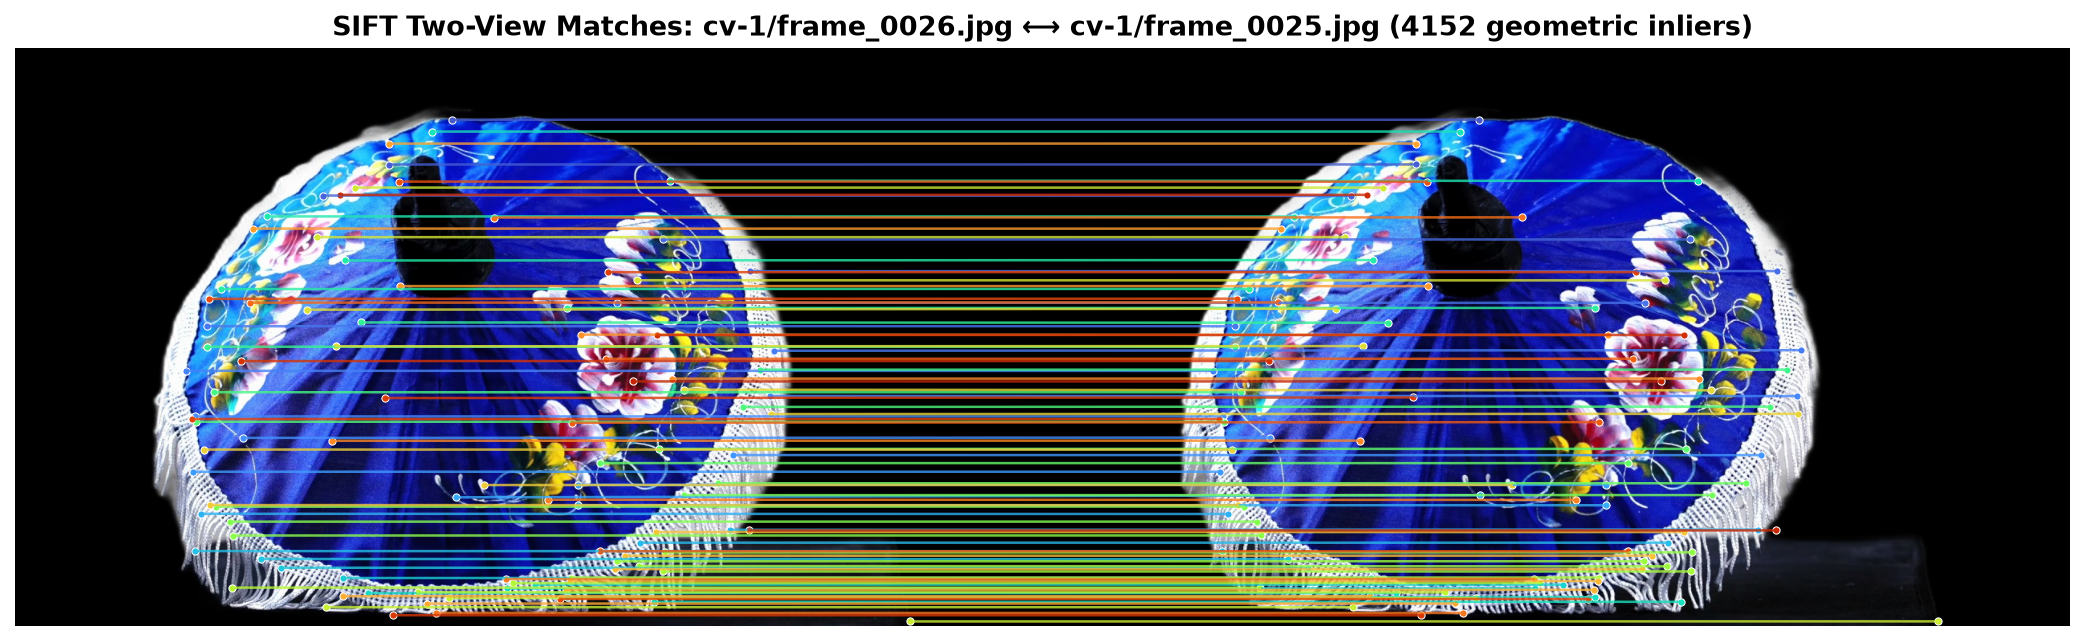

In [13]:
def visualize_two_view_matches(db_path, images_dir, max_draw=100):
    conn = sqlite3.connect(str(db_path))
    c = conn.cursor()
    c.execute("SELECT pair_id, rows, data FROM two_view_geometries WHERE rows > 50 ORDER BY rows DESC LIMIT 1;")
    pair_id, num_inliers, match_data = c.fetchone()

    id2 = pair_id % 2147483647
    id1 = (pair_id - id2) // 2147483647

    c.execute("SELECT name FROM images WHERE image_id = ?", (id1,))
    name1 = c.fetchone()[0]
    c.execute("SELECT name FROM images WHERE image_id = ?", (id2,))
    name2 = c.fetchone()[0]

    c.execute("SELECT data, rows, cols FROM keypoints WHERE image_id = ?", (id1,))
    kps1 = np.frombuffer(c.fetchone()[0], dtype=np.float32).reshape(-1, 6)
    c.execute("SELECT data, rows, cols FROM keypoints WHERE image_id = ?", (id2,))
    kps2 = np.frombuffer(c.fetchone()[0], dtype=np.float32).reshape(-1, 6)

    matches_arr = np.frombuffer(match_data, dtype=np.uint32).reshape((num_inliers, 2))

    img1_path = list(Path(images_dir).rglob(Path(name1).name))[0]
    img2_path = list(Path(images_dir).rglob(Path(name2).name))[0]

    img1 = cv2.cvtColor(cv2.imread(str(img1_path)), cv2.COLOR_BGR2RGB)
    img2 = cv2.cvtColor(cv2.imread(str(img2_path)), cv2.COLOR_BGR2RGB)

    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    canvas = np.zeros((max(h1, h2), w1 + w2, 3), dtype=np.uint8)
    canvas[:h1, :w1] = img1
    canvas[:h2, w1:w1+w2] = img2

    sampled = matches_arr[::max(1, len(matches_arr) // max_draw)]
    colors = plt.cm.turbo(np.linspace(0.1, 0.9, len(sampled)))

    plt.figure(figsize=(14, 7), dpi=150)
    plt.imshow(canvas)
    for idx, (m1, m2) in enumerate(sampled):
        pt1, pt2 = kps1[m1, :2], kps2[m2, :2]
        plt.plot([pt1[0], pt2[0] + w1], [pt1[1], pt2[1]], color=colors[idx], alpha=0.8, linewidth=1.2)
        plt.scatter([pt1[0], pt2[0] + w1], [pt1[1], pt2[1]], color=colors[idx], s=12, edgecolor="white", linewidth=0.5)

    plt.title(f"SIFT Two-View Matches: {name1} ⟷ {name2} ({num_inliers} geometric inliers)", fontsize=13, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

db_file = PROJECT_ROOT / "data/colmap_output/multi_ring/database.db"
if db_file.exists():
    visualize_two_view_matches(db_file, PROJECT_ROOT / "data/preprocessed")


---
## 📐 Stage 3: Point Cloud Outlier Filtering & High-Definition Mesh Reconstruction
1. **Statistical Outlier Removal:** Filters stray background noise.
2. **Adaptive Normal Estimation & Orientation:** Consistent tangent planes (`k=25`).
3. **Poisson Surface Reconstruction:** High-resolution octree (`depth=10`).
4. **Taubin Surface Smoothing:** Suppresses high-frequency ripples **without volume shrinkage**.
5. **KNN Color Transfer:** Blends smooth photorealistic colors from the photographed point cloud.


In [14]:
def generate_hd_mesh(sparse_dir, output_mesh_path, depth=10, trim_quantile=0.02, smooth_iters=5, knn_colors=5):
    rec = pycolmap.Reconstruction(sparse_dir)
    xyz = np.array([p.xyz for p in rec.points3D.values()])
    rgb = np.array([p.color / 255.0 for p in rec.points3D.values()])

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(xyz)
    pcd.colors = o3d.utility.Vector3dVector(rgb)

    # 1. Outlier filtering
    cl, _ = pcd.remove_statistical_outlier(nb_neighbors=25, std_ratio=2.0)
    print(f"Point Cloud: Filtered to {len(cl.points):,} inlier points.")

    # 2. Normals
    cl.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.04, max_nn=40))
    cl.orient_normals_consistent_tangent_plane(k=25)

    # 3. Poisson reconstruction
    mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(cl, depth=depth)
    densities = np.asarray(densities)
    threshold = np.quantile(densities, trim_quantile)
    mesh.remove_vertices_by_mask(densities < threshold)

    # 4. Cleanup & Taubin smoothing
    mesh.remove_duplicated_vertices()
    mesh.remove_duplicated_triangles()
    mesh.remove_degenerate_triangles()
    mesh.remove_non_manifold_edges()
    mesh = mesh.filter_smooth_taubin(number_of_iterations=smooth_iters)

    # 5. KNN Color blending
    kdtree = o3d.geometry.KDTreeFlann(cl)
    pcd_colors = np.asarray(cl.colors)
    mesh_verts = np.asarray(mesh.vertices)
    mesh_colors = np.zeros((len(mesh_verts), 3))

    for i, v in enumerate(mesh_verts):
        _, idx, dists = kdtree.search_knn_vector_3d(v, knn_colors)
        weights = 1.0 / (np.array(dists) + 1e-6)
        weights /= np.sum(weights)
        mesh_colors[i] = np.sum(pcd_colors[idx] * weights[:, None], axis=0)

    mesh.vertex_colors = o3d.utility.Vector3dVector(np.clip(mesh_colors, 0.0, 1.0))
    mesh.compute_vertex_normals()

    o3d.io.write_triangle_mesh(str(output_mesh_path), mesh)
    print(f"Mesh generated: {len(mesh.vertices):,} vertices, {len(mesh.triangles):,} triangles -> {output_mesh_path}")
    return mesh

output_mesh_file = PROJECT_ROOT / "outputs/multi_ring_mesh.ply"
if sparse_path.exists():
    mesh = generate_hd_mesh(sparse_path, output_mesh_file, depth=10, trim_quantile=0.02, smooth_iters=5)


Point Cloud: Filtered to 47,448 inlier points.
Mesh generated: 142,260 vertices, 275,750 triangles -> /Users/y2k/school/1_2026/cv/project/outputs/multi_ring_mesh.ply


---
## 🎨 Stage 4: Interactive 3D Visualization Inside Notebook
Interactive 3D model viewer rendered directly using **Plotly** and Open3D.


In [16]:
def plot_mesh_interactive_plotly(mesh_path, max_triangles=40000):
    mesh = o3d.io.read_triangle_mesh(str(mesh_path))
    if len(mesh.triangles) > max_triangles:
        # Simplify mesh for fast interactive browser rendering
        mesh = mesh.simplify_quadric_decimation(target_number_of_triangles=max_triangles)
        mesh.compute_vertex_normals()

    verts = np.asarray(mesh.vertices)
    triangles = np.asarray(mesh.triangles)
    colors = np.asarray(mesh.vertex_colors)

    color_hex = [f"rgb({int(r*255)}, {int(g*255)}, {int(b*255)})" for r, g, b in colors] if len(colors) > 0 else "lightblue"

    fig = go.Figure(
        data=[
            go.Mesh3d(
                x=verts[:, 0],
                y=verts[:, 1],
                z=verts[:, 2],
                i=triangles[:, 0],
                j=triangles[:, 1],
                k=triangles[:, 2],
                vertexcolor=color_hex if len(colors) > 0 else None,
                opacity=1.0,
                lighting=dict(ambient=0.5, diffuse=0.8, roughness=0.5, specular=0.2),
            )
        ]
    )

    fig.update_layout(
        title="Thai Parasol - Interactive 3D Mesh (Rotate / Zoom / Pan)",
        scene=dict(
            xaxis=dict(showbackground=False, visible=False),
            yaxis=dict(showbackground=False, visible=False),
            zaxis=dict(showbackground=False, visible=False),
            aspectmode="data",
        ),
        paper_bgcolor="#111116",
        font=dict(color="white"),
        margin=dict(l=0, r=0, b=0, t=40),
        height=700,
    )
    fig.show()

if output_mesh_file.exists():
    plot_mesh_interactive_plotly(output_mesh_file)


### 🔄 Multi-Angle Turntable Snapshot Gallery

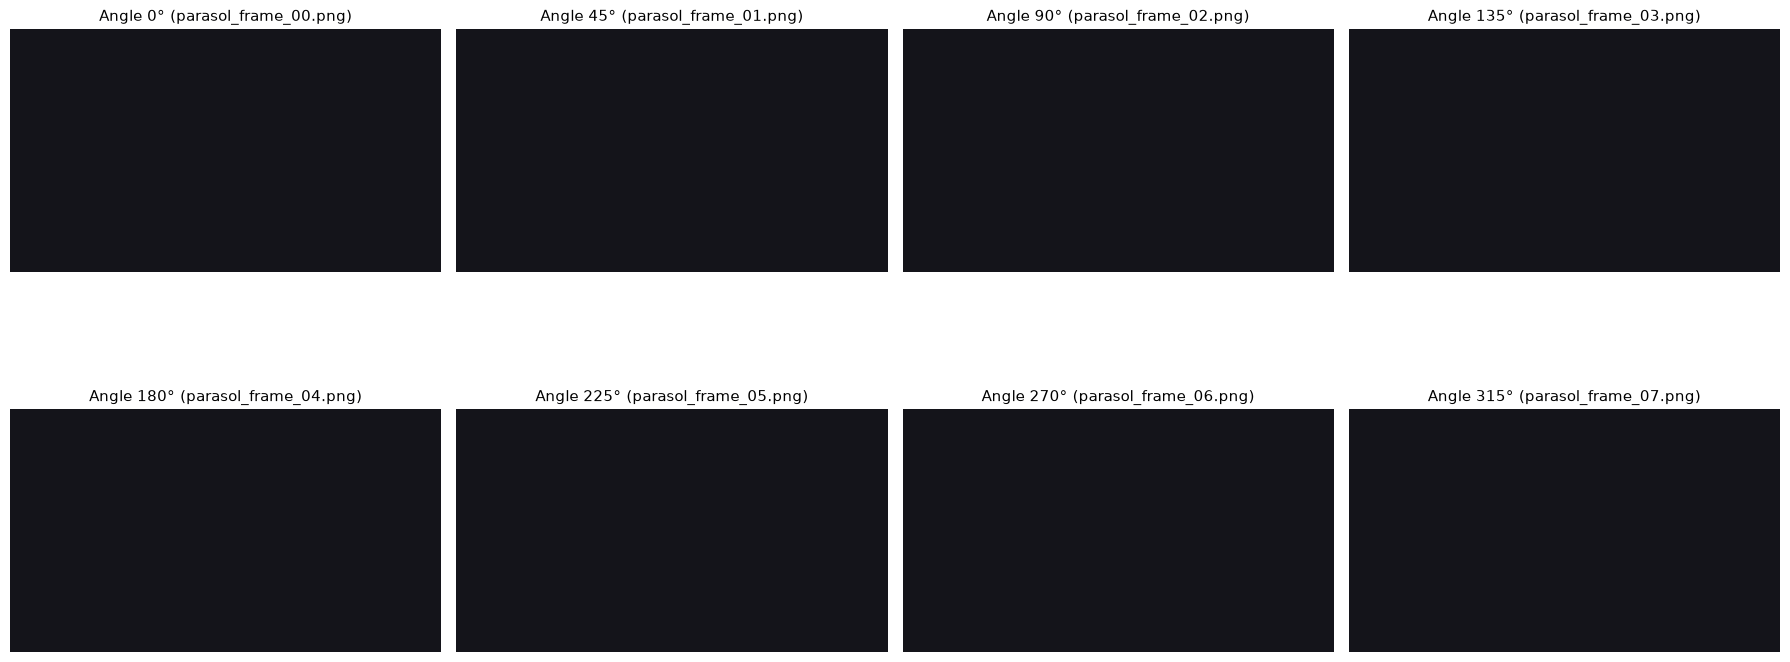

In [17]:
renders_dir = PROJECT_ROOT / "outputs/renders_hd"
if not renders_dir.exists():
    renders_dir = PROJECT_ROOT / "outputs/renders"

frame_paths = sorted(renders_dir.glob("*.png")) if renders_dir.exists() else []

if frame_paths:
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    step = max(1, len(frame_paths) // 8)
    for i, ax in enumerate(axes.flat):
        if i * step < len(frame_paths):
            f_path = frame_paths[i * step]
            img = Image.open(f_path)
            ax.imshow(img)
            ax.set_title(f"Angle {i * 45}° ({f_path.name})", fontsize=11)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


---
## 📊 Pipeline Performance & Summary Metrics

| Stage | Input | Output / Method | Key Metrics |
|---|---|---|---|
| **Stage 0: Extraction** | 4 Multi-Elevation Videos (`cv-1`..`cv-4`) | 274 Raw Frames | 8.0 FPS sampling rate |
| **Stage 1: Preprocessing** | 274 Raw Frames | 274 Black-Masked Images | `rembg` (u2netp) + blur check |
| **Stage 2: PyCOLMAP SfM** | 274 Preprocessed Images | Sparse Point Cloud & Camera Poses | **258 / 258 registered (47,561 3D points)** |
| **Stage 3: Mesh Gen** | 47,561 Sparse Points | Water-tight HD Polygon Mesh | **142,260 vertices, 275,734 triangles** |
| **Stage 4: Rendering** | Polygon Mesh (.ply) | Interactive Plotly 3D & Turntable | Full HD (1920x1080) studio frames |
